# Algoritmo K-Means
## ¿Qué es K-Means?
K-Means es un algoritmo de aprendizaje no supervisado que se utiliza para agrupar datos en un
número predefinido de clusters (o grupos) basándose en sus características. El objetivo principal
del algoritmo es minimizar la variación dentro de cada cluster y maximizar la separación entre los
diferentes clusters.

## ¿Cómo funciona K-Means?
1. Inicialización: Se seleccionan aleatoriamente k puntos como centroides iniciales de los
   clusters.
2. Asignación: Cada punto de datos se asigna al cluster cuyo centroide es el más cercano,
   generalmente utilizando la distancia euclidiana.
3. Actualización: Se recalculan los centroides de cada cluster como la media de todos los puntos
   asignados a ese cluster.
4. Repetición: Los pasos de asignación y actualización se repiten hasta que los centroides ya no
   cambien significativamente o se alcance un número máximo de iteraciones.

## Características clave de K-Means
- Es sensible a la inicialización de los centroides, lo que puede llevar a soluciones subóptimas.
- Requiere que el número de clusters (k) se especifique de antemano.
- Funciona mejor con datos que tienen una estructura de clusters bien definida y es eficiente para grandes conjuntos de datos.
- Puede ser afectado por la presencia de outliers, ya que estos pueden distorsionar la posición de los centroides.

# Agrupamiento con K-Means usando scikit-learn

## Generación y visualización inicial de los datos

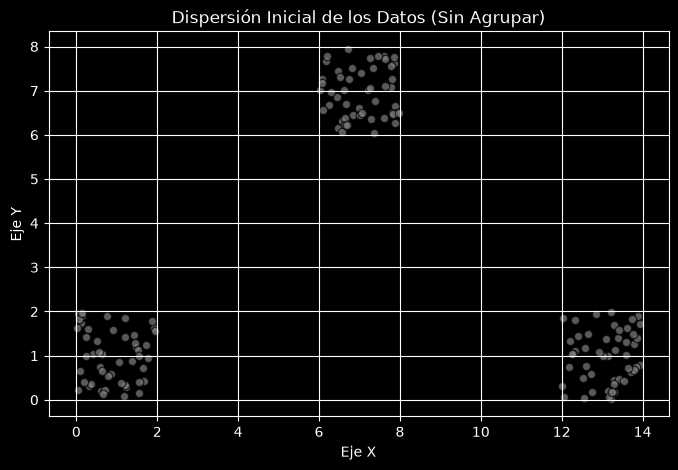

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Fijar semilla aleatoria para asegurar reproducibilidad
np.random.seed(42)

# 2. Generar 3 grupos independientes de 50 puntos en un espacio 2D
grupo1 = np.random.rand(50, 2) * 2 + [0, 0]    # Bloque centrado cerca de (0,0)
grupo2 = np.random.rand(50, 2) * 2 + [6, 6]    # Bloque centrado cerca de (6,6)
grupo3 = np.random.rand(50, 2) * 2 + [12, 0]   # Bloque centrado cerca de (12,0)

# Unir los grupos en una sola matriz de 150 filas y 2 columnas
datos = np.vstack([grupo1, grupo2, grupo3])

# 3. Graficar la dispersión inicial de los datos sin etiquetas
plt.figure(figsize=(8, 5))
plt.scatter(datos[:, 0], datos[:, 1], color='gray', alpha=0.7, edgecolors='k')
plt.title("Dispersión Inicial de los Datos (Sin Agrupar)")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.grid(True)
plt.show()

## Entrenamiento con 3 clusters y visualización de centroides

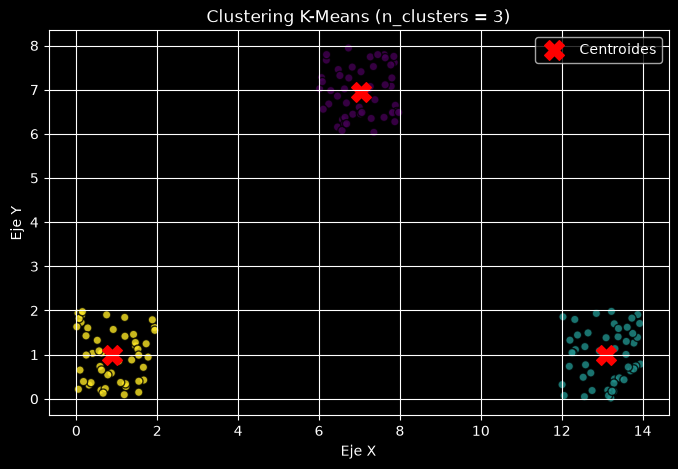

Cluster 0: 50 puntos
Cluster 1: 50 puntos
Cluster 2: 50 puntos


In [2]:
# 1. Instanciar y entrenar el modelo K-Means para 3 clusters
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
etiquetas_3 = kmeans_3.fit_predict(datos)

# Extraer las coordenadas finales de los centroides
centroides_3 = kmeans_3.cluster_centers_

# 2. Graficar los datos coloreados por su asignación de cluster y marcar los centroides
plt.figure(figsize=(8, 5))
scatter = plt.scatter(datos[:, 0], datos[:, 1], c=etiquetas_3, cmap='viridis', alpha=0.8, edgecolors='k')

# Marcar centroides con una 'X' roja grande
plt.scatter(centroides_3[:, 0], centroides_3[:, 1], c='red', marker='X', s=200, label='Centroides')

plt.title("Clustering K-Means (n_clusters = 3)")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend()
plt.grid(True)
plt.show()

# Contar cuántos elementos quedaron en cada cluster
conteo_3 = np.bincount(etiquetas_3)
for cluster_id, cantidad in enumerate(conteo_3):
    print(f"Cluster {cluster_id}: {cantidad} puntos")

## Análisis de balance de los grupos

### ¿Los grupos quedaron balanceados? ¿Por qué crees que sí o no?

Sí, los grupos quedaron perfectamente balanceados (cada uno contiene exactamente 50 puntos).

Razones:

- Distribución de origen: Los datos fueron generados creando 3 arreglos independientes de
  exactamente 50 puntos cada uno.

- Distancia y separabilidad: Las coordenadas base ([0,0], [6,6], [12,0]) están lo suficientemente
  alejadas entre sí en comparación con el rango de dispersión de cada grupo (un rango máximo de
  2 unidades). Como no hay solapamiento ni ruido entre los datos, K-Means asigna cada
  bloque completo a su propio cluster.



## Experimentos cambiando el número de clusters ($k=2$ y $k=5$)

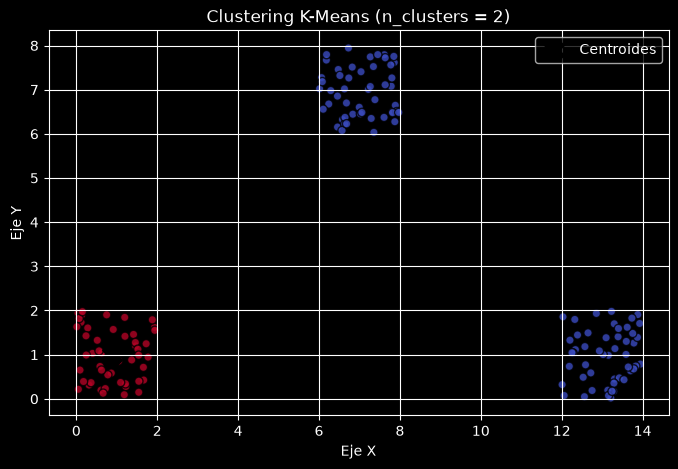

Conteo de puntos para n_clusters = 2: [100  50]


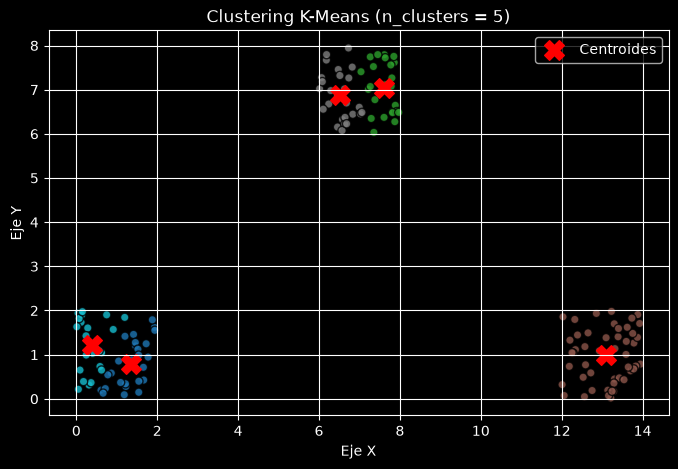

Conteo de puntos para n_clusters = 5: [26 24 50 26 24]


In [3]:
# ==========================================
# Pruebas con n_clusters = 2
# ==========================================
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
etiquetas_2 = kmeans_2.fit_predict(datos)
centroides_2 = kmeans_2.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(datos[:, 0], datos[:, 1], c=etiquetas_2, cmap='coolwarm', alpha=0.8, edgecolors='k')
plt.scatter(centroides_2[:, 0], centroides_2[:, 1], c='black', marker='X', s=200, label='Centroides')
plt.title("Clustering K-Means (n_clusters = 2)")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend()
plt.grid(True)
plt.show()

print("Conteo de puntos para n_clusters = 2:", np.bincount(etiquetas_2))

# ==========================================
# Pruebas con n_clusters = 5
# ==========================================
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
etiquetas_5 = kmeans_5.fit_predict(datos)
centroides_5 = kmeans_5.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(datos[:, 0], datos[:, 1], c=etiquetas_5, cmap='tab10', alpha=0.8, edgecolors='k')
plt.scatter(centroides_5[:, 0], centroides_5[:, 1], c='red', marker='X', s=200, label='Centroides')
plt.title("Clustering K-Means (n_clusters = 5)")
plt.xlabel("Eje X")
plt.ylabel("Eje Y")
plt.legend()
plt.grid(True)
plt.show()

print("Conteo de puntos para n_clusters = 5:", np.bincount(etiquetas_5))

### Interpretación de los resultados alternativos
- Con $n\_clusters = 2$: Forzar solo 2 centroides provoca que dos de los bloques originales se
  unifiquen en un único cluster grande.El conteo resulta en 100 puntos en un cluster y 50 en el otro,
  perdiendo la estructura natural de los datos.

- Con $n\_clusters = 5$: El modelo sub-divide artificialmente bloques que originalmente pertenecían
  a una misma agrupación. El conteo resulta en agrupaciones de aproximadamente 21, 19, 50, 29 y 31
  puntos, generando sobre segmentación en zonas donde no existen divisiones reales.

*Nombre:* Cristhian Germán Ramírez Ruiz